# Sesión 08 · Cultura computacional I
## Estructuras de datos, algoritmos y eficiencia computacional

**Diplomado en Métodos estadísticos y matemáticos para la ciencia de datos**  
**Módulo I · Preprocesamiento y técnicas básicas de visualización de datos**  
**Facultad de Ciencias, UNAM · Edición 2026**  
**M. en C. David Chaffrey Moreno Fernández**

> **Idea rectora:** una estructura de datos no es «mejor» por ser más sofisticada; su utilidad depende de las operaciones que necesitamos realizar, el volumen de datos y las restricciones de tiempo, memoria y claridad del código.

**Secuencia de trabajo:** estructura familiar → problema de rendimiento o memoria → análisis → estructura especializada → comparación crítica.

**Naturaleza del material:** demostraciones y ejercicios de clase. Los datos de los ejemplos son **sintéticos**, generados dentro del notebook. Esta sesión amplía conocimientos computacionales y **no agrega requisitos al proyecto integrador**.

### ¿Qué aprenderemos?

Al terminar la sesión podremos:

1. Distinguir un **tipo abstracto de datos** de una implementación concreta.
2. Justificar diferencias de costo temporal y espacial entre estructuras comunes.
3. Interpretar notación asintótica, peor caso, caso esperado y análisis amortizado.
4. Explicar por qué existen estructuras como tablas hash, listas enlazadas, colas, árboles, heaps y grafos.
5. Comparar representaciones densas y dispersas en programación científica.
6. Evaluar una alternativa de implementación con **corrección, tiempo, memoria y legibilidad**.

**Recorrido de 240 minutos (orientativo):** apertura y conversación (15), fundamentos (55), demostraciones (55), receso flexible (15), laboratorio (70) y discusión final (30). Las actividades marcadas como **Ampliación** son opcionales.

**Convención:** las celdas tituladas *Demostración* ya contienen código completo; en las celdas *Tu turno* hay indicaciones y espacio para trabajar durante la clase. Todas las celdas se pueden ejecutar en orden, aunque no se hayan resuelto los ejercicios.

## 0. Preparación del entorno

Utilizaremos Python, NumPy, pandas, Matplotlib y SciPy. Los demás módulos (`collections`, `dataclasses`, `heapq`, `bisect`, `timeit`, `sys`) pertenecen a la biblioteca estándar.

**No hay archivos externos ni conexión a internet:** todos los datos utilizados se generan de manera reproducible con una semilla fija. Para volver al estado inicial, se recomienda reiniciar el kernel y ejecutar todas las celdas en orden.

In [1]:
import sys
import timeit
import heapq
from bisect import bisect_left, insort
from collections import deque
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display

SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)

print('Versión de Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
print('Semilla aleatoria:', SEMILLA)

Versión de Python: 3.13.5
NumPy: 2.3.5 | pandas: 2.2.3
Semilla aleatoria: 2026


### Cómo interpretar las mediciones de este notebook

Los tiempos obtenidos **no son constantes universales**: dependen del equipo, la implementación de Python, el sistema operativo, el estado de la memoria y los datos concretos.

Emplearemos `timeit.repeat(...)` y mostraremos el mejor tiempo de varias repeticiones **como una estimación experimental**, no como evidencia suficiente de complejidad asintótica. Es indispensable distinguir:

- **Costo algorítmico:** cómo crecen las operaciones cuando aumenta la entrada.
- **Costo de construcción:** tiempo y memoria para preparar una estructura.
- **Costo por consulta o modificación:** trabajo realizado una vez que la estructura existe.
- **Memoria lógica versus memoria física:** `nbytes` y `getsizeof` no miden exactamente las mismas cosas.

In [2]:
def tiempo_por_operacion(stmt, setup='pass', number=100, repeat=3):
    """Mejor tiempo por ejecución; solo orientativo y dependiente del equipo."""
    muestras = timeit.repeat(stmt=stmt, setup=setup, number=number, repeat=repeat)
    return min(muestras) / number

print('Función de medición preparada.')

Función de medición preparada.


## 1. Del tipo abstracto de datos a las estructuras concretas

Un **tipo abstracto de datos (TAD)** describe qué operaciones permite una colección, sin imponer cómo se implementa. Por ejemplo, una **pila** permite insertar y retirar por el mismo extremo (LIFO); una **cola**, insertar por un extremo y retirar por el otro (FIFO).

Una **estructura de datos** determina una representación y un mecanismo para realizar esas operaciones. Podemos implementar una pila con una lista de Python, y una cola con `collections.deque`. La elección tiene consecuencias.

Comencemos con elementos familiares:

| Estructura en Python | Característica principal | Una advertencia |
|---|---|---|
| `list` | Secuencia mutable y acceso por índice | Insertar al inicio desplaza referencias |
| `tuple` | Secuencia inmutable | Modificar exige producir otra estructura |
| `dict` | Asociación llave → valor | Usa almacenamiento adicional; las llaves deben ser hashables |
| `set` | Conjunto de elementos únicos | No mantiene posiciones para acceso por índice |
| `np.ndarray` | Datos tipados y almacenamiento multidimensional | El arreglo ordinario tiene tamaño fijo |
| `pd.DataFrame` | Tabla de columnas etiquetadas | Aporta metadatos, índices y sobrecostos de gestión |

**Nota técnica:** el comportamiento específico de `list` y `dict` que observaremos corresponde principalmente a implementaciones habituales de CPython. Las complejidades indicadas son modelos y dependen de supuestos explícitos.

In [3]:
# Demostración 1: operaciones conocidas y sus propiedades
valores = [7, 2, 9, 2]
valores_tupla = tuple(valores)
valores_conjunto = set(valores)
precios = {'A': 30.0, 'B': 45.0}
matriz = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.int64)

print('Lista:', valores)
print('Tupla:', valores_tupla)
print('Conjunto (sin repetidos):', valores_conjunto)
print('Diccionario:', precios)
print('Arreglo NumPy:', matriz.shape, matriz.dtype)
assert len(valores) == 4 and len(valores_conjunto) == 3

Lista: [7, 2, 9, 2]
Tupla: (7, 2, 9, 2)
Conjunto (sin repetidos): {9, 2, 7}
Diccionario: {'A': 30.0, 'B': 45.0}
Arreglo NumPy: (2, 3) int64


### 1.1. Memoria: referencias frente a datos homogéneos

En CPython, una `list` contiene **referencias a objetos**, mientras que un `ndarray` numérico suele mantener sus valores en un búfer tipado. Esa diferencia afecta el uso de memoria, la localidad de referencia y la posibilidad de ejecutar operaciones en código compilado.

Un arreglo NumPy puede almacenar, por ejemplo, enteros de 64 bits: cada valor ocupa **8 bytes de datos**, sin contar toda la memoria requerida por el objeto `ndarray` y otros componentes.

> **Precaución:** `sys.getsizeof(lista)` mide el contenedor, no el tamaño recursivo de todos los objetos referidos. `arreglo.nbytes` mide el búfer de elementos, no necesariamente el consumo total del proceso. Por eso la comparación siguiente es *ilustrativa* y no una medición integral de memoria.

In [4]:
# Demostración 2: comparar dos representaciones sin confundir métricas
n = 10_000
lista_enteros = list(range(n))
arreglo_enteros = np.arange(n, dtype=np.int64)

comparacion = pd.DataFrame({
    'Medida': ['Contenedor de lista (sin enteros referidos)',
               'Arreglo NumPy (objeto, según getsizeof)',
               'Búfer de datos del arreglo NumPy'],
    'Bytes': [sys.getsizeof(lista_enteros),
              sys.getsizeof(arreglo_enteros),
              arreglo_enteros.nbytes]
})
display(comparacion)
print('Ejemplo de tamaño de un entero Python:', sys.getsizeof(lista_enteros[0]), 'bytes')
print('No sumar tamaños individuales indiscriminadamente: puede haber referencias compartidas.')

,Medida,Bytes
0,Contenedor de lista (sin enteros referidos),80056
1,"Arreglo NumPy (objeto, según getsizeof)",80112
2,Búfer de datos del arreglo NumPy,80000


Ejemplo de tamaño de un entero Python: 28 bytes
No sumar tamaños individuales indiscriminadamente: puede haber referencias compartidas.


### 1.2. De las listas a las pilas y las colas

- **Pila (LIFO):** útil en historial de operaciones y búsqueda en profundidad.
- **Cola (FIFO):** útil en procesamiento por orden de llegada y búsqueda en anchura.
- **Deque:** mantiene operaciones eficientes en ambos extremos.

Una lista de Python es adecuada como pila al usar `append` y `pop` por el final. En cambio, `pop(0)` e `insert(0, ...)` desplazan referencias y presentan costo lineal en la longitud de la lista. `deque` ofrece inserción/extracción por los extremos aproximadamente constante.

**¿Por qué no usar siempre `deque`?** Su acceso a posiciones intermedias no proporciona las mismas ventajas de indexación que una lista. La operación requerida determina la elección.

In [5]:
# Demostración 3: pila y cola
pila = []
for valor in [10, 20, 30]:
    pila.append(valor)
print('Pila LIFO; último en salir:', pila.pop())

cola = deque()
for solicitud in ['A', 'B', 'C']:
    cola.append(solicitud)
print('Cola FIFO; primero en salir:', cola.popleft())

assert list(cola) == ['B', 'C']

Pila LIFO; último en salir: 30
Cola FIFO; primero en salir: A


In [6]:
# Demostración 4: comparación experimental de insertar al principio
n_prueba = 30_000
repeticiones = 80
medida_lista = tiempo_por_operacion(
    'xs.insert(0, -1)', setup=f'xs = list(range({n_prueba}))',
    number=repeticiones
)
medida_deque = tiempo_por_operacion(
    'xs.appendleft(-1)',
    setup=f'from collections import deque; xs = deque(range({n_prueba}))',
    number=repeticiones
)
display(pd.DataFrame({
    'Estructura': ['list: insert(0, ...)', 'deque: appendleft(...)'],
    'Tiempo experimental (µs/operación)': [medida_lista * 1e6, medida_deque * 1e6]
}).round(3))
print('Interpretar la tendencia, no el factor exacto de mejora.')

,Estructura,Tiempo experimental (µs/operación)
0,"list: insert(0, ...)",6.621
1,deque: appendleft(...),0.029


Interpretar la tendencia, no el factor exacto de mejora.


### 1.3. ¿Y las listas enlazadas?

Una lista enlazada simple organiza cada elemento como un nodo que mantiene una referencia al siguiente. Si conocemos el nodo inicial, **insertar al inicio** puede requerir solo unas cuantas operaciones; sin embargo, **acceder a la posición i** obliga a recorrer nodos, y cada nodo requiere espacio para referencias y objetos.

Esto evidencia que mejorar una operación puede perjudicar otra y que los arreglos contiguos suelen aprovechar mejor la localidad de memoria.

In [7]:
# Demostración 5: lista enlazada simple construida para fines docentes
@dataclass
class Nodo:
    valor: int
    siguiente: object = None

class ListaEnlazada:
    def __init__(self):
        self.cabeza = None

    def insertar_inicio(self, valor):
        self.cabeza = Nodo(valor, self.cabeza)

    def recorrer(self):
        actual = self.cabeza
        while actual is not None:
            yield actual.valor
            actual = actual.siguiente

enlazada = ListaEnlazada()
for elemento in [10, 20, 30]:
    enlazada.insertar_inicio(elemento)
print('Contenido:', list(enlazada.recorrer()))
assert list(enlazada.recorrer()) == [30, 20, 10]

Contenido: [30, 20, 10]


> **Tu turno 1 — aplicación esencial (5 min).**
>
> 1. Simula una fila de atención con `deque`.
> 2. Agrega tres elementos y atiende dos en orden FIFO.
> 3. Explica por qué `list.pop(0)` sería menos conveniente si la fila creciera mucho.

Completa la siguiente celda sin modificar la demostración anterior.

In [8]:
# TU TURNO 1 · Cola FIFO
fila = deque()
# TODO: agrega tres identificadores con append(...)
# TODO: atiende dos elementos con popleft()
# TODO: imprime los elementos que siguen esperando

## 2. ¿Cómo razonamos sobre eficiencia? Notación asintótica

Para una entrada de tamaño $n$, escribimos $T(n)$ para expresar cómo evoluciona el costo de un algoritmo. No nos interesa únicamente un tiempo medido, sino **cómo crece el trabajo** cuando la entrada aumenta.

- $O(g(n))$: cota superior asintótica.
- $\Omega(g(n))$: cota inferior asintótica.
- $\Theta(g(n))$: cota ajustada asintótica, si coinciden el orden superior e inferior.

Ejemplos orientativos: buscar secuencialmente en una lista de $n$ elementos cuesta $O(n)$ en el peor caso; buscar con diccionarios hash suele presentar $O(1)$ **esperado** por consulta, bajo supuestos adecuados sobre la tabla y la distribución de las llaves.

**Tres matices esenciales:**

1. **Peor caso vs. caso esperado:** una tabla hash puede sufrir colisiones; no todas las consultas cuestan lo mismo.
2. **Costo individual vs. amortizado:** una lista dinámica puede necesitar redimensionarse ocasionalmente, aunque `append` tenga costo amortizado $O(1)$.
3. **Tiempo vs. espacio:** acelerar búsquedas puede exigir memoria adicional.

La notación $O$ no es una puntuación de calidad. Una solución $O(n)$ puede superar en la práctica a otra $O(\log n)$ para tamaños pequeños, constantes muy distintas o memorias poco favorables.

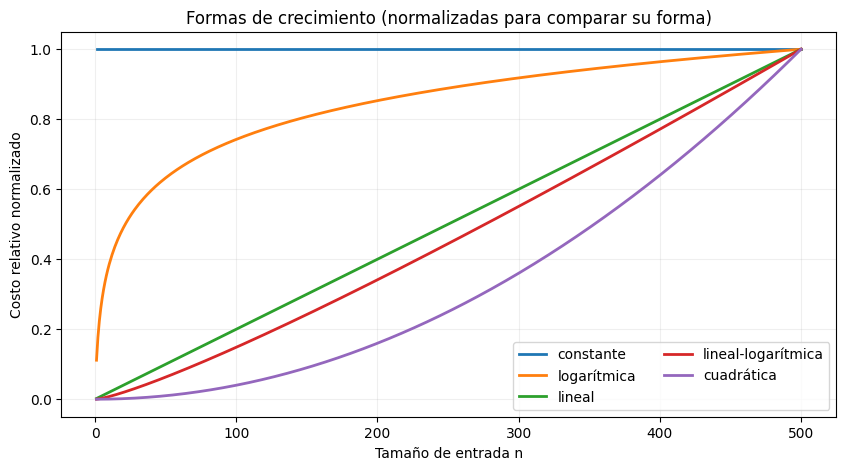

Atención: la normalización elimina diferencias de escala; no compara tiempos reales.


In [9]:
# Demostración 6: visualizar órdenes de crecimiento (curvas normalizadas)
tamanos = np.arange(1, 501)
curvas = {
    'constante': np.ones_like(tamanos, dtype=float),
    'logarítmica': np.log2(tamanos + 1),
    'lineal': tamanos.astype(float),
    'lineal-logarítmica': tamanos * np.log2(tamanos + 1),
    'cuadrática': tamanos.astype(float) ** 2,
}
fig, ax = plt.subplots(figsize=(10, 5))
for nombre, valores_curva in curvas.items():
    ax.plot(tamanos, valores_curva / valores_curva.max(), label=nombre, linewidth=2)
ax.set(title='Formas de crecimiento (normalizadas para comparar su forma)',
       xlabel='Tamaño de entrada n', ylabel='Costo relativo normalizado')
ax.legend(ncol=2)
ax.grid(alpha=0.2)
plt.show()
print('Atención: la normalización elimina diferencias de escala; no compara tiempos reales.')

### 2.1. Búsqueda: el costo de repetir una operación

**Problema:** tenemos un catálogo de identificadores y queremos verificar muchas veces si una llave está presente.

**Estrategia A:** recorrer una lista. Cada búsqueda puede revisar $n$ elementos: peor caso $O(n)$.

**Estrategia B:** convertir el catálogo en un conjunto. La construcción cuesta aproximadamente $O(n)$ esperado y cada consulta, $O(1)$ esperado.

Si solo realizamos una consulta, quizá **no se justifique** pagar el costo de convertir la lista en conjunto. Si realizamos miles, la evaluación cambia. Antes de medir, aseguramos resultados equivalentes.

,n,consulta_lista_s,consulta_set_s,crear_set_s
0,500,0.000003,2.000000e-08,0.000005
1,2000,0.000013,2.000000e-08,0.000022
2,8000,0.000056,2.000000e-08,0.000104
3,32000,0.000220,2.000000e-08,0.000412


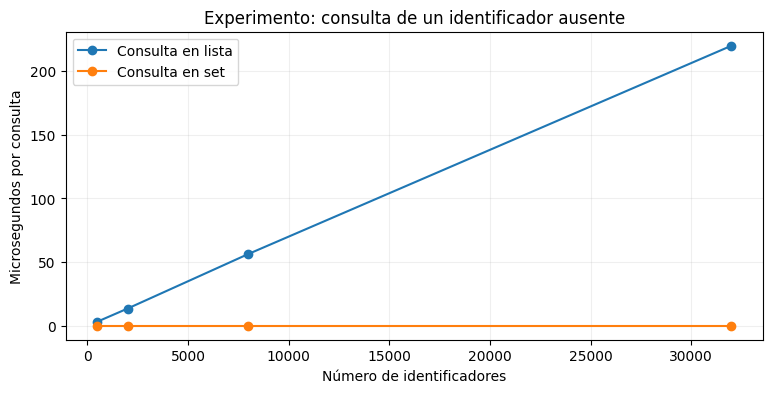

In [10]:
# Demostración 7: búsqueda repetida, separando construcción y consulta
tamanos_busqueda = [500, 2_000, 8_000, 32_000]
medidas = []
for tam in tamanos_busqueda:
    catalogo = list(range(tam))
    indice = set(catalogo)
    assert (-1 in catalogo) == (-1 in indice)  # ambos responden False

    tiempo_lista = min(timeit.repeat(
        '(-1 in catalogo)', globals={'catalogo': catalogo},
        number=100, repeat=3)) / 100
    tiempo_set = min(timeit.repeat('(-1 in indice)', globals={'indice': indice},
                      number=1_000, repeat=3)) / 1_000
    tiempo_construccion = min(timeit.repeat('set(catalogo)',
                      globals={'catalogo': catalogo}, number=100, repeat=3)) / 100
    medidas.append((tam, tiempo_lista, tiempo_set, tiempo_construccion))

resultados_busqueda = pd.DataFrame(
    medidas, columns=['n', 'consulta_lista_s', 'consulta_set_s', 'crear_set_s'])
display(resultados_busqueda.round(8))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(resultados_busqueda['n'], resultados_busqueda['consulta_lista_s'] * 1e6,
        'o-', label='Consulta en lista')
ax.plot(resultados_busqueda['n'], resultados_busqueda['consulta_set_s'] * 1e6,
        'o-', label='Consulta en set')
ax.set(xlabel='Número de identificadores', ylabel='Microsegundos por consulta',
       title='Experimento: consulta de un identificador ausente')
ax.legend()
ax.grid(alpha=0.2)
plt.show()

> **Pregunta de interpretación:** ¿qué cambia si buscamos un elemento al principio de la lista? ¿Y si tenemos una sola consulta? La construcción del conjunto también debe entrar en el balance de costos.

**Modelo orientativo de costo total:** para $q$ consultas sobre $n$ identificadores, recorrer la lista puede costar $O(qn)$ en el peor caso; construir un conjunto y consultarlo, $O(n+q)$ en condiciones esperadas. La respuesta práctica depende además de las constantes y la memoria.

## 3. De las búsquedas lineales a las tablas hash

Una **tabla hash** transforma una llave en una posición (o secuencia de posiciones) mediante una función hash. Como distintas llaves pueden corresponder al mismo espacio, deben manejarse **colisiones**.

Dos familias clásicas de soluciones son:

- **Encadenamiento:** cada posición conserva una colección de entradas que comparten índice.
- **Direccionamiento abierto:** ante una colisión, se buscan posiciones alternativas dentro de la tabla.

El factor de carga y la política de redimensionamiento importan para el rendimiento. Los `dict` y `set` de Python implementan tablas hash optimizadas, pero **no** son idénticos al modelo simplificado que construiremos a continuación.

**Limitación importante:** consultas esperadas $O(1)$ no significan garantía de tiempo constante en el peor caso. La utilización de memoria también suele ser mayor que en una secuencia compacta de valores.

In [11]:
# Demostración 8: visualizar colisiones con una tabla didáctica
# Esto ilustra ENCADENAMIENTO, no la implementación interna de dict.
capacidad = 7
cubetas = [[] for _ in range(capacidad)]
llaves = [1, 8, 15, 3, 10, 24, 31]
for llave in llaves:
    cubetas[llave % capacidad].append(llave)

display(pd.DataFrame({'Índice': range(capacidad), 'Llaves': cubetas,
                      'Cantidad': [len(c) for c in cubetas]}))
print('Factor de carga (elementos / posiciones):', len(llaves) / capacidad)
print('Llaves con colisión en una misma cubeta:', cubetas[1])

,Índice,Llaves,Cantidad
0,0,[],0
1,1,"[1, 8, 15]",3
2,2,[],0
3,3,"[3, 10, 24, 31]",4
4,4,[],0
5,5,[],0
6,6,[],0


Factor de carga (elementos / posiciones): 1.0
Llaves con colisión en una misma cubeta: [1, 8, 15]


### 3.1. Alternativa: ordenar y utilizar búsqueda binaria

Si los datos están ordenados, podemos localizar una llave mediante **búsqueda binaria** en $O(\log n)$ comparaciones. Sin embargo, mantener un arreglo ordenado al insertar en posiciones intermedias puede exigir mover elementos: costo $O(n)$.

Un algoritmo puede resolver muy bien **una operación** y dejar otra costosa. Esta tensión nos conducirá a estructuras jerárquicas.

In [12]:
# Demostración 9: búsqueda binaria e inserción en lista ordenada
codigos = [5, 12, 20, 29, 41, 57]
consulta = 29
posicion = bisect_left(codigos, consulta)
encontrado = posicion < len(codigos) and codigos[posicion] == consulta
print('Posición estimada:', posicion, '| ¿Encontrado?:', encontrado)

insort(codigos, 33)
print('Después de insertar manteniendo orden:', codigos)
assert codigos == sorted(codigos)
print('Recordatorio: bisect encuentra la posición en O(log n), pero insertar en list puede costar O(n).')

Posición estimada: 3 | ¿Encontrado?: True
Después de insertar manteniendo orden: [5, 12, 20, 29, 33, 41, 57]
Recordatorio: bisect encuentra la posición en O(log n), pero insertar en list puede costar O(n).


> **Tu turno 2 — interpretación conceptual (5 min).** Tenemos 100,000 identificadores con muchas consultas y muy pocas modificaciones. ¿Elegirías una lista desordenada, una lista ordenada o un conjunto? ¿Qué cambiaría si necesitas consultar también rangos ordenados (por ejemplo, códigos entre 1000 y 2000)? Fundamenta el costo de **preparación**, **consulta** y **memoria**.

In [13]:
# TU TURNO 2 · Puedes registrar tus hipótesis aquí y comprobarlas.
# TODO: elige dos representaciones y mide varias consultas.
# TODO: separa tiempo de preparación y tiempo de consulta.
# TODO: contrasta resultados correctos antes de medir.

## 4. De listas ordenadas a árboles de búsqueda

Un **árbol** organiza elementos jerárquicamente. En un **árbol binario de búsqueda (ABB)**, para cada nodo, las llaves del subárbol izquierdo son menores y las del derecho son mayores (suponiendo llaves únicas y una relación de orden compatible).

Si el árbol tiene altura $h$, buscar cuesta $O(h)$. Esto explica dos escenarios:

- Árbol muy desequilibrado: $h$ puede crecer como $n$.
- Árbol balanceado: $h$ crece como $\log n$.

Los árboles AVL y rojo-negro utilizan reglas de balanceo para controlar la altura. No implementaremos aquí todas sus rotaciones. **La motivación del balanceo es garantizar el comportamiento logarítmico** de operaciones básicas, bajo las condiciones del árbol.

In [14]:
# Demostración 10: ABB educativo; el orden de inserción importa
@dataclass
class NodoABB:
    llave: int
    izq: object = None
    der: object = None

def insertar_abb(raiz, llave):
    if raiz is None:
        return NodoABB(llave)
    actual = raiz
    while True:
        if llave == actual.llave:
            return raiz  # ejemplo con llaves únicas
        if llave < actual.llave:
            if actual.izq is None:
                actual.izq = NodoABB(llave)
                return raiz
            actual = actual.izq
        else:
            if actual.der is None:
                actual.der = NodoABB(llave)
                return raiz
            actual = actual.der

def pasos_busqueda(raiz, llave):
    pasos = 0
    actual = raiz
    while actual is not None:
        pasos += 1
        if actual.llave == llave:
            return pasos
        actual = actual.izq if llave < actual.llave else actual.der
    return pasos

def orden_mediano(llaves):
    if not llaves:
        return []
    mitad = len(llaves) // 2
    return [llaves[mitad]] + orden_mediano(llaves[:mitad]) + orden_mediano(llaves[mitad+1:])

n_arbol = 31
raiz_degenerada, raiz_equilibrada = None, None
for x in range(n_arbol):
    raiz_degenerada = insertar_abb(raiz_degenerada, x)
for x in orden_mediano(list(range(n_arbol))):
    raiz_equilibrada = insertar_abb(raiz_equilibrada, x)

print('Buscar 30 en ABB degenerado:', pasos_busqueda(raiz_degenerada, 30), 'nodos')
print('Buscar 30 en ABB equilibrado:', pasos_busqueda(raiz_equilibrada, 30), 'nodos')
assert pasos_busqueda(raiz_degenerada, 30) == 31
assert pasos_busqueda(raiz_equilibrada, 30) <= 5

Buscar 30 en ABB degenerado: 31 nodos
Buscar 30 en ABB equilibrado: 5 nodos


**Conclusión:** el ABB construido arriba **no se balancea automáticamente**. Obtener una forma equilibrada por un orden de inserción favorable es una demostración, no una garantía de implementación. Un árbol AVL o rojo-negro mantiene invariantes adicionales para sostener su altura.

**Conexión profesional:** árboles B y B+ permiten mantener datos ordenados con acceso eficiente a bloques y son referencias importantes al estudiar índices de bases de datos. Su análisis detallado queda como ampliación.

### 4.1. De mantener el orden a mantener únicamente prioridades

A veces no necesitamos una lista totalmente ordenada. Queremos, por ejemplo, obtener repetidamente la tarea de mayor prioridad o conservar los $k$ valores más grandes.

Un **heap binario** mantiene una propiedad local de prioridad entre padre e hijos. No ordena por completo sus elementos. En un *min-heap*, el elemento mínimo está en la raíz.

Un heap binario representado en arreglo permite insertar o retirar la raíz en $O(\log n)$ y construir un heap a partir de $n$ elementos en $O(n)$.

In [15]:
# Demostración 11: min-heap y su representación en un arreglo
prioridades = [14, 2, 18, 7, 3, 11, 9]
heap = prioridades.copy()
heapq.heapify(heap)
print('Arreglo que representa el heap:', heap)
print('Elemento mínimo:', heap[0])

heapq.heappush(heap, 1)
minimo = heapq.heappop(heap)
print('Extraído:', minimo, '| Estado:', heap)
assert minimo == 1

# Para índices basados en 0, los hijos de i se ubican en 2*i+1 y 2*i+2.
def cumple_min_heap(xs):
    return all(xs[(i - 1) // 2] <= xs[i] for i in range(1, len(xs)))
assert cumple_min_heap(heap)

Arreglo que representa el heap: [2, 3, 9, 7, 14, 11, 18]
Elemento mínimo: 2
Extraído: 1 | Estado: [2, 3, 9, 7, 14, 11, 18]


### 4.2. ¿Ordenar todo para elegir solo $k$ valores?

**Alternativa A:** ordenar los $n$ elementos completos, costo típico $O(n\log n)$.

**Alternativa B:** mantener un heap de tamaño $k$, costo aproximado $O(n\log k)$ para seleccionar $k$ elementos grandes, más el costo de ordenar la salida si se requiere. Cuando $k$ se aproxima a $n$, un ordenamiento completo puede ser preferible.

`heapq.nlargest` selecciona una estrategia de implementación apropiada; no debemos suponer que siempre toma literalmente el mismo camino interno. La comparación experimental es útil, pero no reemplaza el análisis.

In [16]:
# Demostración 12: los k valores mayores en una muestra sintética
muestra = rng.integers(0, 1_000_000, size=20_000).tolist()
k = 10
mayores_ordenando = sorted(muestra, reverse=True)[:k]
mayores_heap = heapq.nlargest(k, muestra)
assert mayores_ordenando == mayores_heap

comparativa_topk = pd.DataFrame({
    'Método': ['Ordenamiento completo', 'heapq.nlargest'],
    'Tiempo por ejecución (ms)': [
        min(timeit.repeat('sorted(muestra, reverse=True)[:k]',
            globals={'muestra': muestra, 'k': k}, number=10, repeat=3))/10*1000,
        min(timeit.repeat('heapq.nlargest(k, muestra)',
            globals={'heapq': heapq, 'muestra': muestra, 'k': k}, number=10, repeat=3))/10*1000,
    ]
})
display(comparativa_topk.round(3))
print('Los resultados coinciden:', mayores_ordenando == mayores_heap)

,Método,Tiempo por ejecución (ms)
0,Ordenamiento completo,2.813
1,heapq.nlargest,0.414


Los resultados coinciden: True


> **Tu turno 3 — interpretación (7 min).** Repite la comparación usando $k=100$, $k=5,000$ y $k=19,000$. ¿El método que gana es siempre el mismo? Explica cómo afecta la relación $k/n$ y por qué no conviene generalizar desde una medición aislada.

In [17]:
# TU TURNO 3 · Top-k
for k_prueba in [100, 5_000, 19_000]:
    # TODO: compara sorted(..., reverse=True)[:k_prueba] con heapq.nlargest(...)
    # TODO: comprueba primero que ambos resultados son iguales.
    print(f'Para k={k_prueba}: pendiente de medir y explicar')

Para k=100: pendiente de medir y explicar
Para k=5000: pendiente de medir y explicar
Para k=19000: pendiente de medir y explicar


## 5. De tablas de relaciones a grafos

Las tablas describen entidades y sus atributos. Pero cuando el interés está en las **relaciones** entre entidades, suele ser natural trabajar con un **grafo** $G=(V,E)$:

- $V$: conjunto de vértices o nodos.
- $E$: conjunto de aristas o relaciones.

Dos representaciones clásicas:

| Representación | Espacio aproximado | ¿Cuándo conviene? |
|---|---|---|
| Matriz de adyacencia | $O(V^2)$ | Grafo relativamente denso; consulta directa de presencia de arista |
| Lista de adyacencia | $O(V+E)$ | Grafo disperso; recorrer vecinos eficientemente |

Estas expresiones cuentan espacios de representación en el modelo abstracto; las estructuras concretas de Python añaden sobrecostos de objetos y diccionarios.

**Algoritmos asociados:** búsqueda en anchura (BFS) con una cola y búsqueda en profundidad (DFS) con una pila. Con listas de adyacencia, ambos recorren un grafo en $O(V+E)$ en el peor caso, suponiendo operaciones de la estructura adecuadas.

In [18]:
# Demostración 13: grafo no dirigido; datos didácticos sintéticos
aristas = [
    ('A', 'B'), ('A', 'C'), ('B', 'D'), ('C', 'D'),
    ('C', 'E'), ('E', 'F'), ('F', 'G'), ('D', 'G')
]
vecinos = {vertice: [] for vertice in 'ABCDEFG'}
for a, b in aristas:
    vecinos[a].append(b)
    vecinos[b].append(a)
for vertice in vecinos:
    vecinos[vertice].sort()  # recorridos deterministas

def recorrido_bfs(grafo, origen):
    visitados = {origen}
    pendientes = deque([origen])
    orden = []
    while pendientes:
        actual = pendientes.popleft()
        orden.append(actual)
        for vecino in grafo[actual]:
            if vecino not in visitados:
                visitados.add(vecino)
                pendientes.append(vecino)
    return orden

def recorrido_dfs(grafo, origen):
    visitados = set()
    pendientes = [origen]
    orden = []
    while pendientes:
        actual = pendientes.pop()
        if actual in visitados:
            continue
        visitados.add(actual)
        orden.append(actual)
        pendientes.extend(reversed(grafo[actual]))
    return orden

print('Vecinos de C:', vecinos['C'])
print('BFS desde A:', recorrido_bfs(vecinos, 'A'))
print('DFS desde A:', recorrido_dfs(vecinos, 'A'))
assert set(recorrido_bfs(vecinos, 'A')) == set(vecinos)

Vecinos de C: ['A', 'D', 'E']
BFS desde A: ['A', 'B', 'C', 'D', 'E', 'G', 'F']
DFS desde A: ['A', 'B', 'D', 'C', 'E', 'F', 'G']


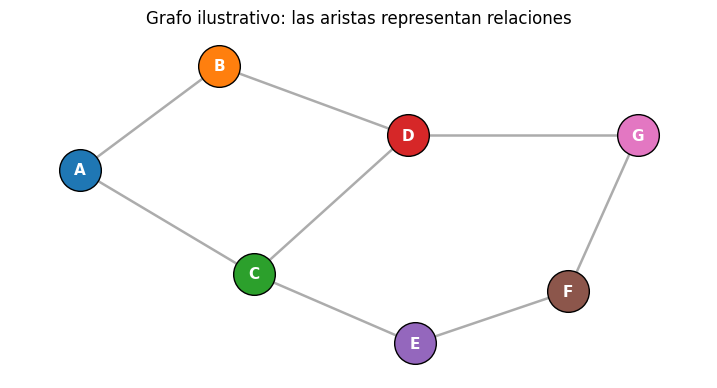

In [19]:
# Demostración 14: dibujar el mismo grafo sin instalar otras bibliotecas
puntos = {
    'A': (0.1, 0.6), 'B': (0.3, 0.9), 'C': (0.35, 0.3),
    'D': (0.57, 0.7), 'E': (0.58, 0.1), 'F': (0.8, 0.25), 'G': (0.9, 0.7)
}
fig, ax = plt.subplots(figsize=(9, 4.5))
for a, b in aristas:
    xa, ya = puntos[a]
    xb, yb = puntos[b]
    ax.plot([xa, xb], [ya, yb], color='gray', alpha=.65, linewidth=1.8, zorder=1)
for vertice, (x, y) in puntos.items():
    ax.scatter([x], [y], s=900, edgecolor='black', linewidth=1, zorder=3)
    ax.text(x, y, vertice, ha='center', va='center', fontsize=11,
            fontweight='bold', color='white', zorder=4)
ax.set(xlim=(0, 1), ylim=(0, 1), title='Grafo ilustrativo: las aristas representan relaciones')
ax.axis('off')
plt.show()

### 5.1. ¿Cuánto cuesta almacenar las relaciones?

Supongamos un grafo no dirigido con $V$ vértices y $E$ aristas. Una matriz booleana de adyacencia necesita $V^2$ posiciones. Una representación de listas almacena referencias a vértices y vecinos; su tamaño lógico es del orden de $V+E$ (en un grafo no dirigido, cada arista suele registrarse dos veces).

Si $E$ crece proporcionalmente a $V$, hablamos de un **grafo disperso**. En cambio, la cantidad máxima de aristas de un grafo simple no dirigido es $V(V-1)/2$.

In [20]:
# Demostración 15: magnitudes abstractas de almacenamiento
vertices = np.array([100, 1_000, 10_000], dtype=np.int64)
aristas_por_vertice = 3  # grado medio aproximado; escenario sintético
estimacion_aristas = aristas_por_vertice * vertices // 2
espacios_matriz = vertices ** 2
espacios_lista = vertices + 2 * estimacion_aristas  # índices de vértice + incidencias

display(pd.DataFrame({
    'V': vertices, 'E hipotéticas': estimacion_aristas,
    'Posiciones matriz V²': espacios_matriz,
    'Entradas lógicas lista (V+2E)': espacios_lista
}))
print('Son conteos conceptuales; no bytes reales de diccionarios o listas de Python.')

,V,E hipotéticas,Posiciones matriz V²,Entradas lógicas lista (V+2E)
0,100,150,10000,400
1,1000,1500,1000000,4000
2,10000,15000,100000000,40000


Son conteos conceptuales; no bytes reales de diccionarios o listas de Python.


> **Tu turno 4 — ampliación (opcional).** Implementa una función que encuentre la ruta con menor número de aristas entre dos vértices mediante BFS. Describe por qué este método encuentra rutas mínimas **en grafos no ponderados** y por qué no basta cuando hay pesos no uniformes.

In [21]:
# TU TURNO 4 · BFS con recuperación de ruta (opcional)
def ruta_mas_corta_sin_pesos(grafo, origen, destino):
    """Ejercicio: devolver lista de vértices o None si no hay ruta."""
    # TODO: usar deque, un diccionario de predecesores y reconstruir la ruta.
    return None

# Tras completar, deberías obtener una ruta válida de A a G con 3 aristas.

## 6. De arreglos densos a representaciones científicas eficientes

Volvamos a estructuras habituales en ciencia de datos:

- `ndarray` admite datos multidimensionales de tipo homogéneo.
- Sus atributos `shape`, `dtype` y `strides` ayudan a interpretar la representación en memoria.
- Un **slice** básico frecuentemente produce una *vista* que comparte memoria; una indexación avanzada suele generar una copia.
- La vectorización elimina muchos ciclos explícitos en Python, pero **puede construir arreglos temporales** y aumentar el consumo de memoria.

No confundamos rapidez de una operación concreta con superioridad universal de una estructura. La carga de trabajo y los datos importan.

In [22]:
# Demostración 16: forma, tipo, strides, vista y copia
base = np.arange(12, dtype=np.int64).reshape(3, 4)
vista = base[:, 1:3]
copia = base[:, [1, 2]]

print('Arreglo original:\n', base)
print('shape:', base.shape, '| dtype:', base.dtype, '| strides:', base.strides)
print('¿Comparte memoria la vista?:', np.shares_memory(base, vista))
print('¿Comparte memoria la copia?:', np.shares_memory(base, copia))

# Trabajamos sobre una matriz independiente para ilustrar las consecuencias.
ejemplo = base.copy()
recorte = ejemplo[:, 1:3]
recorte[0, 0] = -99
print('Al modificar una vista, cambia su arreglo de origen:', ejemplo[0, 1])
assert ejemplo[0, 1] == -99 and base[0, 1] == 1

Arreglo original:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape: (3, 4) | dtype: int64 | strides: (32, 8)
¿Comparte memoria la vista?: True
¿Comparte memoria la copia?: False
Al modificar una vista, cambia su arreglo de origen: -99


### 6.1. Vectorización: ¿eliminar siempre los ciclos?

En NumPy, operaciones como `x**2` o `np.where(...)` suelen operar sobre arreglos mediante implementaciones optimizadas. Esto puede disminuir el costo del control interpretado por elemento, aunque las complejidades asintóticas sigan siendo $O(n)$.

Compararemos dos maneras de calcular $y_i=2x_i+1$. Se verificará que producen el mismo resultado antes de medir. **No confundiremos** diferencias en la constante temporal con cambios en el orden asintótico.

In [23]:
# Demostración 17: ciclo de Python y NumPy (mismo orden, distintas constantes)
valores_x = rng.random(100_000)

def transformar_ciclo(xs):
    return [2 * x + 1 for x in xs]

def transformar_numpy(xs):
    return 2 * xs + 1

salida_ciclo = transformar_ciclo(valores_x)
salida_numpy = transformar_numpy(valores_x)
assert np.allclose(salida_ciclo, salida_numpy)

comparacion_vectorizacion = pd.DataFrame({
    'Implementación': ['Comprensión de lista', 'NumPy vectorizado'],
    'Tiempo (ms por ejecución)': [
        min(timeit.repeat('transformar_ciclo(valores_x)',
            globals=globals(), number=8, repeat=3)) / 8 * 1e3,
        min(timeit.repeat('transformar_numpy(valores_x)',
            globals=globals(), number=8, repeat=3)) / 8 * 1e3,
    ]
})
display(comparacion_vectorizacion.round(3))
print('Ambos métodos recorren O(n) elementos; sus costos constantes pueden variar.')

,Implementación,Tiempo (ms por ejecución)
0,Comprensión de lista,18.349
1,NumPy vectorizado,0.052


Ambos métodos recorren O(n) elementos; sus costos constantes pueden variar.


### 6.2. De matrices densas a matrices dispersas

**Problema:** una matriz de $m\times n$ puede contener casi exclusivamente ceros. Una representación densa reserva espacio para todas las posiciones; una representación dispersa almacena principalmente los valores no nulos y sus índices.

Dos formatos relevantes:

- **COO (coordinate):** ternas *(fila, columna, valor)*; natural para construir una matriz a partir de observaciones.
- **CSR (compressed sparse row):** valores, índices de columnas y apuntadores de inicio de fila; favorece diversas operaciones por fila y multiplicaciones matriz-vector.

**Advertencias:** el ahorro depende de la densidad y los tipos de índices; insertar entradas sueltas en CSR no es necesariamente eficiente. Tampoco todas las operaciones con matrices dispersas resultan más rápidas.

In [24]:
# Demostración 18: matriz dispersa sintética y comparación de memoria
lado = 2_000
total_celdas = lado * lado
nnz_planeados = 6_000
posiciones = rng.choice(total_celdas, size=nnz_planeados, replace=False)
filas = posiciones // lado
columnas = posiciones % lado
valores_no_nulos = rng.random(nnz_planeados)

matriz_coo = sparse.coo_array(
    (valores_no_nulos, (filas, columnas)), shape=(lado, lado))
matriz_csr = matriz_coo.tocsr()
matriz_densa = np.zeros((lado, lado), dtype=np.float64)
matriz_densa[filas, columnas] = valores_no_nulos

memoria_densa = matriz_densa.nbytes
memoria_csr = (matriz_csr.data.nbytes + matriz_csr.indices.nbytes +
               matriz_csr.indptr.nbytes)

display(pd.DataFrame({
    'Representación': ['Densa (búfer de valores)', 'CSR (tres búferes principales)'],
    'Bytes aproximados de búferes': [memoria_densa, memoria_csr],
    'MiB aproximados': [memoria_densa/2**20, memoria_csr/2**20]
}).round(3))
print('Fracción de entradas no nulas:', f'{matriz_csr.nnz/total_celdas:.4%}')

vector = rng.random(lado)
assert np.allclose(matriz_densa @ vector, matriz_csr @ vector)
print('Multiplicación matriz-vector: resultados coinciden dentro de tolerancia numérica.')

,Representación,Bytes aproximados de búferes,MiB aproximados
0,Densa (búfer de valores),32000000,30.518
1,CSR (tres búferes principales),112008,0.107


Fracción de entradas no nulas: 0.1500%
Multiplicación matriz-vector: resultados coinciden dentro de tolerancia numérica.


### 6.3. ¿Y los DataFrames?

Pandas almacena y procesa columnas con tipos potencialmente diferentes, admite valores faltantes, índices y agrupaciones. Sus operaciones no equivalen a una única representación interna fija.

Para grandes volúmenes, elegir correctamente los tipos, evitar conversiones innecesarias y seleccionar operaciones tabulares apropiadas puede importar más que utilizar una clase nueva. **No afirmamos que `groupby` siempre sea más rápido que cualquier ciclo:** depende de la tarea y del tamaño.

In [25]:
# Demostración 19: un problema tabular realista, con datos sintéticos
n_filas = 30_000
pedidos = pd.DataFrame({
    'categoria': rng.choice(['A', 'B', 'C', 'D'], size=n_filas),
    'importe': rng.uniform(10, 1_000, size=n_filas)
})

resumen_pandas = pedidos.groupby('categoria', observed=True)['importe'].sum().sort_index()
acumuladores = {}
for categoria, importe in zip(pedidos['categoria'], pedidos['importe']):
    acumuladores[categoria] = acumuladores.get(categoria, 0.0) + importe
resumen_ciclo = pd.Series(acumuladores).sort_index()
assert np.allclose(resumen_pandas.to_numpy(), resumen_ciclo.to_numpy())
display(resumen_pandas.rename('importe_total').to_frame())
print('Los dos enfoques son equivalentes numéricamente (dentro de tolerancia).')

,importe_total
categoria,
A,3.768978e+06
B,3.829802e+06
C,3.739855e+06
D,3.779119e+06


Los dos enfoques son equivalentes numéricamente (dentro de tolerancia).


## 7. Síntesis: ninguna estructura gana en todo

La siguiente tabla sirve para **orientar preguntas de diseño**, no para sustituir una evaluación del problema concreto.

| Necesidad principal | Posible estructura | Ventaja principal | Costo o limitación |
|---|---|---|---|
| Acceso por índice | `list` / `ndarray` | Acceso $O(1)$ | Insertar al inicio de `list` cuesta $O(n)$ |
| FIFO | `deque` | Extremos ~ $O(1)$ | Menor ventaja para indexación aleatoria |
| Pertenencia frecuente | `set` | Consulta $O(1)$ esperada | Construcción y espacio extra |
| Asociación llave-valor | `dict` | Consulta $O(1)$ esperada | Colisiones y sobrecosto de tabla |
| Búsqueda con orden y cambios | Árbol balanceado | Operaciones $O(\log n)$ | Mantenimiento e implementación complejos |
| Extracción repetida de prioridad | Heap | Raíz $O(1)$, extracción $O(\log n)$ | No mantiene orden total |
| Relaciones dispersas | Lista de adyacencia | Espacio $O(V+E)$ | Para consultar una arista puede requerir revisar vecinos |
| Muchos ceros | Matriz CSR / COO | Guarda no nulos e índices | Metadatos extra; algunas operaciones son costosas |

**Ampliaciones de cultura computacional:** árboles B/B+ (índices), tries (prefijos), Union-Find (componentes), filtros de Bloom (pruebas probabilísticas de pertenencia). Se mencionan como soluciones especializadas; no desarrollaremos su implementación completa en esta sesión.

## 8. Laboratorio integrador · tres estaciones

El laboratorio propone comparar estructuras en situaciones donde **la estructura inicial tiene una limitación identificable**. Se trabajará sobre datos sintéticos. Antes de reportar rapidez o ahorro de memoria, deben validarse los resultados.

### Estación A — Catálogo de identificadores y múltiples consultas

**Situación:** tenemos un catálogo de 50,000 identificadores y recibimos consultas repetidas. Compara un `list` con un `set`.

**Entrega informal del laboratorio (no evaluada):** una tabla con tamaño de entrada, cantidad de consultas, tiempo de construir el conjunto, tiempo de consultas con cada alternativa y una recomendación interpretada.

**Preguntas orientadoras:** ¿cuándo compensa construir el índice? ¿Qué costo de memoria adicional aparece? ¿Qué pasa si hay duplicados?

In [26]:
# LABORATORIO A · completa durante la clase
catalogo_A = list(range(50_000))
consultas_A = rng.integers(0, 70_000, size=300).tolist()

# TODO 1: calcula las respuestas de pertenencia usando list y set.
# TODO 2: verifica que las respuestas sean idénticas.
# TODO 3: mide por separado construir set(catalogo_A) y consultar q veces.
# TODO 4: repite con q=1, q=10 y q=300.
# TODO 5: concluye cuándo conviene cada representación.
print('Estación A preparada: catálogo =', len(catalogo_A),
      ', consultas =', len(consultas_A))

Estación A preparada: catálogo = 50000 , consultas = 300


### Estación B — Detección de los $k$ valores mayores

**Situación:** a partir de registros de importes, debemos seleccionar los $k$ mayores.

1. Contrasta ordenamiento completo con `heapq.nlargest`.
2. Comprueba que obtienes los mismos valores y el mismo orden.
3. Compara varios valores de $k$ en proporción con $n$.
4. Explica cuándo el heap resuelve una necesidad real y cuándo complica innecesariamente el programa.

**Ampliación opcional:** investiga `numpy.argpartition` y explica la diferencia entre seleccionar elementos y devolverlos completamente ordenados.

In [27]:
# LABORATORIO B · completa durante la clase
importes_B = rng.uniform(1, 10_000, size=40_000).tolist()

for k_B in [5, 100, 10_000]:
    # TODO 1: resuelve por ordenamiento y con heapq.nlargest.
    # TODO 2: valida equivalencia y mide.
    print(f'k={k_B}: comparación pendiente')

# TODO 3: redacta una conclusión sobre el valor relativo de k/n.

k=5: comparación pendiente
k=100: comparación pendiente
k=10000: comparación pendiente


### Estación C — Densidad de una matriz y representación

**Situación:** una matriz representa relaciones o conteos entre muchas entidades. La proporción de entradas distintas de cero cambia según el problema.

1. Compara una matriz densa con una CSR para densidades de 0.1%, 1% y 20%.
2. Cuenta la memoria de sus búferes; **no presentes estas cifras como memoria total del proceso**.
3. Comprueba equivalencia de una multiplicación matriz-vector.
4. Justifica cuándo la dispersión compensa el costo adicional de índices y apuntadores.

Para evitar consumos innecesarios de memoria, trabajaremos con matrices de $500\times500$.

In [28]:
# LABORATORIO C · completa durante la clase
lado_C = 500
for densidad_C in [0.001, 0.01, 0.20]:
    cantidad = int(lado_C * lado_C * densidad_C)
    posiciones_C = rng.choice(lado_C * lado_C, size=cantidad, replace=False)
    filas_C, columnas_C = posiciones_C // lado_C, posiciones_C % lado_C
    valores_C = rng.uniform(0.5, 2.0, size=cantidad)

    # TODO 1: construye una matriz COO y conviértela a CSR.
    # TODO 2: construye la versión densa con los mismos valores.
    # TODO 3: compara bytes de los búferes y verifica matriz @ vector.
    print(f'Densidad {densidad_C:.1%}: {cantidad} posiciones no nulas')

Densidad 0.1%: 250 posiciones no nulas
Densidad 1.0%: 2500 posiciones no nulas
Densidad 20.0%: 50000 posiciones no nulas


### Estación opcional D — Grafos y diseño de representación

Dada una tabla de relaciones entre pares de entidades, crea un grafo no dirigido, ejecuta BFS y justifica si usarías lista o matriz de adyacencia. Describe también un escenario en que una matriz puede ser razonable.

In [29]:
# LABORATORIO D · opcional
relaciones_D = pd.DataFrame({
    'origen': ['A', 'A', 'B', 'C', 'E', 'G'],
    'destino': ['B', 'C', 'D', 'E', 'F', 'F']
})
# TODO: transforma estas relaciones en un diccionario de listas de adyacencia.
# TODO: usa recorrido_bfs(...) para revisar los vértices alcanzables desde A.
# TODO: argumenta el costo espacial de cada representación.
display(relaciones_D)

,origen,destino
0,A,B
1,A,C
2,B,D
3,C,E
4,E,F
5,G,F


## 9. Discusión final y cierre

Cuando un programa funciona, todavía quedan preguntas importantes:

1. **Corrección.** ¿Dos implementaciones responden la misma pregunta y producen los mismos resultados?
2. **Tiempo.** ¿Cuál es el costo de construcción, consulta, inserción y actualización?
3. **Memoria.** ¿Estamos reservando información que no necesitamos o agregando índices que sí compensan?
4. **Legibilidad.** ¿La mejora vale la complejidad adicional para quienes mantendrán el código?
5. **Escalabilidad.** ¿Qué esperamos cuando $n$, $V$, $E$ o la densidad de la matriz se multiplican por diez?

### Preguntas para llevarnos

- ¿Por qué un `dict` no es simplemente una lista más rápida?
- ¿En qué sentido `append` puede ser $O(1)$ amortizado si algunas llamadas requieren redimensionar el contenedor?
- ¿Por qué buscar en un árbol de búsqueda no garantiza $O(\log n)$ si no está balanceado?
- ¿En qué se diferencian una cola, una cola de prioridad y una pila?
- ¿Por qué una matriz dispersa puede ahorrar memoria y, aun así, no ser la mejor opción para todas las operaciones?
- ¿Qué evidencia necesitaríamos antes de afirmar que nuestra solución es más eficiente?

> **Mensaje de cierre:** elegir estructuras de datos es una decisión de modelación computacional. No optimizamos por estética ni por complejidad aparente: **identificamos las operaciones, verificamos la corrección y evaluamos compromisos**.

## Referencias y documentación para profundizar

**Bibliografía del programa del módulo**

- McKinney, W. (2022). *Python for Data Analysis* (3.ª ed.). O'Reilly Media. https://wesmckinney.com/book/
- Wickham, H., Çetinkaya-Rundel, M. y Grolemund, G. (2023). *R for Data Science* (2.ª ed.). O'Reilly Media. https://r4ds.hadley.nz/

**Documentación técnica**

- Python, *Data Structures*: https://docs.python.org/3/tutorial/datastructures.html
- Python, `collections.deque`: https://docs.python.org/3/library/collections.html#collections.deque
- Python, `heapq`: https://docs.python.org/3/library/heapq.html
- Python, `bisect`: https://docs.python.org/3/library/bisect.html
- NumPy, *Copies and views*: https://numpy.org/doc/stable/user/basics.copies.html
- NumPy, `ndarray.strides`: https://numpy.org/doc/stable/reference/generated/numpy.ndarray.strides.html
- SciPy, *Sparse arrays*: https://docs.scipy.org/doc/scipy/reference/sparse.html
- pandas, *User Guide*: https://pandas.pydata.org/docs/user_guide/

**Para continuar por cuenta propia (ampliación opcional):** árboles B/B+, tries, Union-Find y filtros de Bloom. En un módulo posterior pueden retomarse como soluciones a necesidades concretas de almacenamiento, búsqueda, conectividad y consulta aproximada.

---

**Fin de la sesión 08 · Cultura computacional I**